In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import pandas as pd
from numpy import set_printoptions
from sklearn import set_config
from sklearn.preprocessing import LabelEncoder

from csm500_project.constant import RAW_TRAIN_DATASET_X_PATH, RAW_TRAIN_DATASET_Y_PATH, INFERRED_TARGET_FIELD, \
    RAW_TEST_DATASET_X_PATH, RAW_TEST_DATASET_Y_PATH
from csm500_project.continuous_data_analysis import CONTINUOUS_DATA_FIELDS
from csm500_project.discrete_data_analysis import DROPPED_CATEGORIES, HIGH_CARDINALITY_ENCODED_CATEGORIES, \
    LOW_CARDINALITY_ENCODED_CATEGORIES, X_ORDINAL_ENCODED_CATEGORIES
from csm500_project.model_development import run_model_pipeline
from csm500_project.model_pipeline import get_build_model_pipeline
from csm500_project.target_distribution import plot_target_distribution
from csm500_project.util import split_primary_physical_datasets

set_config(display="diagram", transform_output="pandas")
set_printoptions(precision=2, linewidth=250)

x_train: pd.DataFrame = pd.read_parquet(RAW_TRAIN_DATASET_X_PATH)
y_train: pd.DataFrame = pd.read_parquet(RAW_TRAIN_DATASET_Y_PATH)
x_test: pd.DataFrame = pd.read_parquet(RAW_TEST_DATASET_X_PATH)
y_test: pd.DataFrame = pd.read_parquet(RAW_TEST_DATASET_Y_PATH)

/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


X-Train Null Values:
Organisation Entity                                   0
Description                                           0
Development Classification                            0
Entry Date Year Of Transfer                           0
Entry Date Quarter Of Transfer                        0
Decision Date Year Of Transfer                        0
Decision Date Quarter Of Transfer                     0
LSOA Code                                             0
Council Code                                          0
IMD Rank                                              0
IMD Decile                                            0
In Conservation Area                                  0
Listing Grade                                         0
Geohazards Collapsible Deposits Susceptibility        0
Geohazards Compressible Ground Susceptibility         0
Geohazards Landslides Susceptibility                  0
Geohazards Running Sand Susceptibility                0
Geohazards Shrink Swell Sus

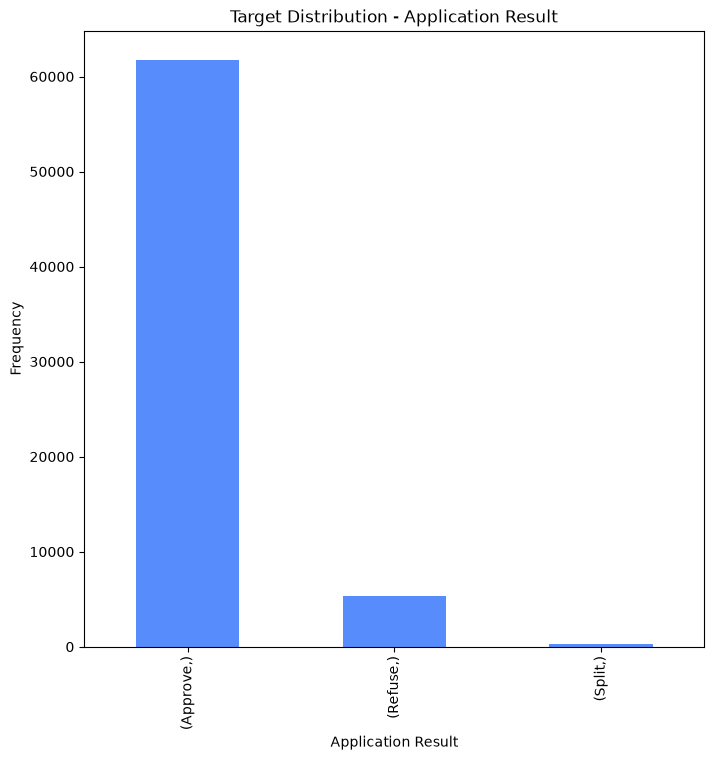

In [2]:
plot_target_distribution(x_train, y_train, "Target Distribution - Application Result")

In [3]:
target_label_encoder: LabelEncoder = LabelEncoder()


def _prepare_target(y: pd.DataFrame) -> None:
    y[INFERRED_TARGET_FIELD] = target_label_encoder.fit_transform(y[INFERRED_TARGET_FIELD])


train_datasets = split_primary_physical_datasets(x_train, y_train, False)
test_datasets = split_primary_physical_datasets(x_test, y_test, False)

primary_x_train: pd.DataFrame = train_datasets['x_primary']
physical_x_train: pd.DataFrame = train_datasets['x_physical']
primary_y_train: pd.DataFrame = train_datasets['y_primary']
physical_y_train: pd.DataFrame = train_datasets['y_physical']

_prepare_target(primary_y_train)
_prepare_target(physical_y_train)

primary_x_test: pd.DataFrame = test_datasets['x_primary']
physical_x_test: pd.DataFrame = test_datasets['x_physical']
primary_y_test: pd.DataFrame = test_datasets['y_primary']
physical_y_test: pd.DataFrame = test_datasets['y_physical']

_prepare_target(primary_y_test)
_prepare_target(physical_y_test)

print("Loaded datasets from Cache.")

Loaded datasets from Cache.


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_glm/_newton_solver.py:439: ConvergenceWarning: Newton solver did not converge after 1 iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_glm/_newton_solver.py:439: ConvergenceWarning: Newton solver did not converge after 1 iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_glm/_newton_solver.py:439: ConvergenceWarning: Newton solver did not converge after 1 iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_en

Log Regression Test Cross Val Accuracy: 0.4498 (0.0132)
Log Regression Test Cross Val Balanced Accuracy: 0.6404 (0.0064)
Log Regression Test Cross Val F1 Macro: 0.2859 (0.0055)
Log Regression Test Cross Val ROC AUC: 0.7373 (0.0100)


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_glm/_newton_solver.py:439: ConvergenceWarning: Newton solver did not converge after 1 iterations.
  warnings.warn(


Classification Report
              precision    recall  f1-score   support

           0       0.95      0.42      0.58     11415
           1       0.15      0.66      0.25      1031
           2       0.01      0.88      0.02        42

    accuracy                           0.44     12488
   macro avg       0.37      0.65      0.28     12488
weighted avg       0.88      0.44      0.55     12488

Confusion Matrix
[[4752 3760 2903]
 [ 236  679  116]
 [   2    3   37]]


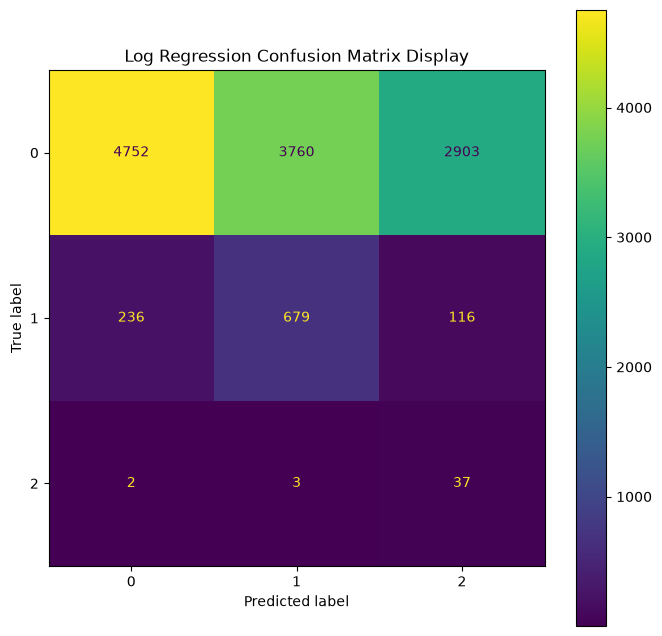

0 [0.8  0.24 0.25 ... 0.34 0.3  0.2 ]
1 [0.17 0.07 0.08 ... 0.6  0.69 0.72]
2 [0.04 0.69 0.67 ... 0.06 0.02 0.08]


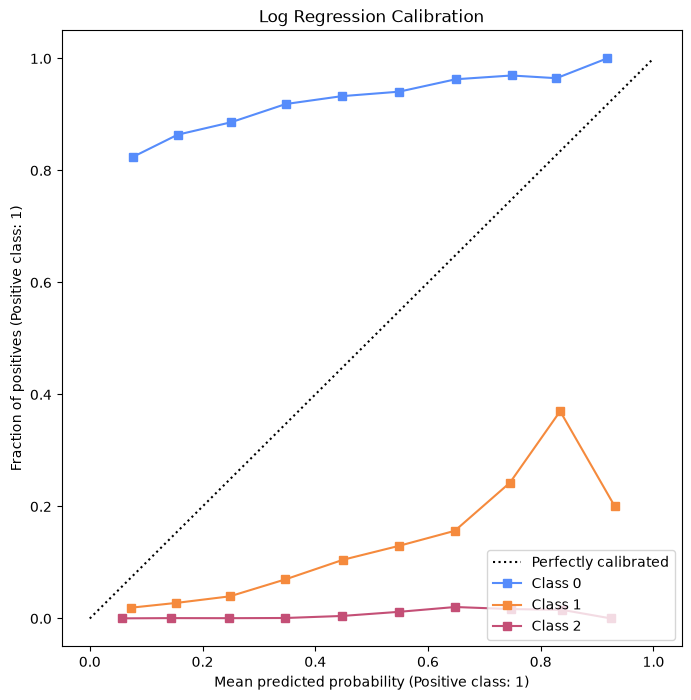

0 [0.8  0.24 0.25 ... 0.34 0.3  0.2 ]
1 [0.17 0.07 0.08 ... 0.6  0.69 0.72]
2 [0.04 0.69 0.67 ... 0.06 0.02 0.08]


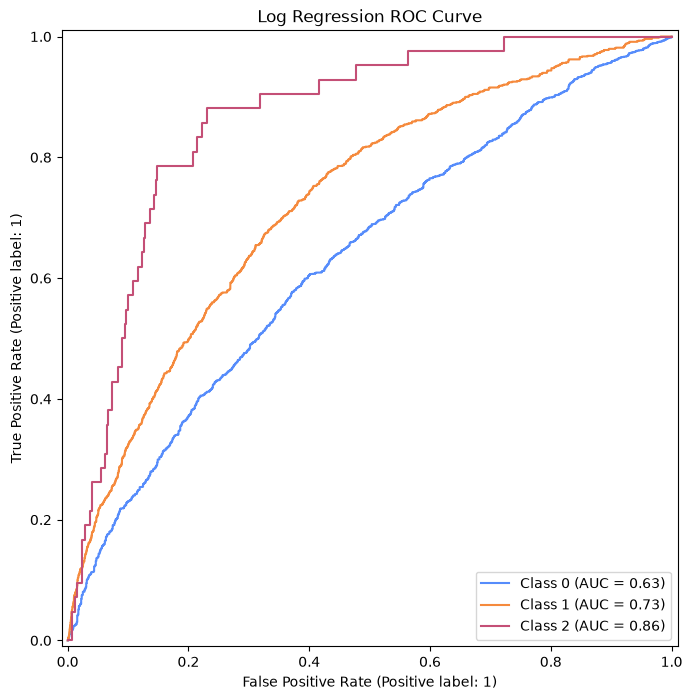

0 [0.8  0.24 0.25 ... 0.34 0.3  0.2 ]
1 [0.17 0.07 0.08 ... 0.6  0.69 0.72]
2 [0.04 0.69 0.67 ... 0.06 0.02 0.08]


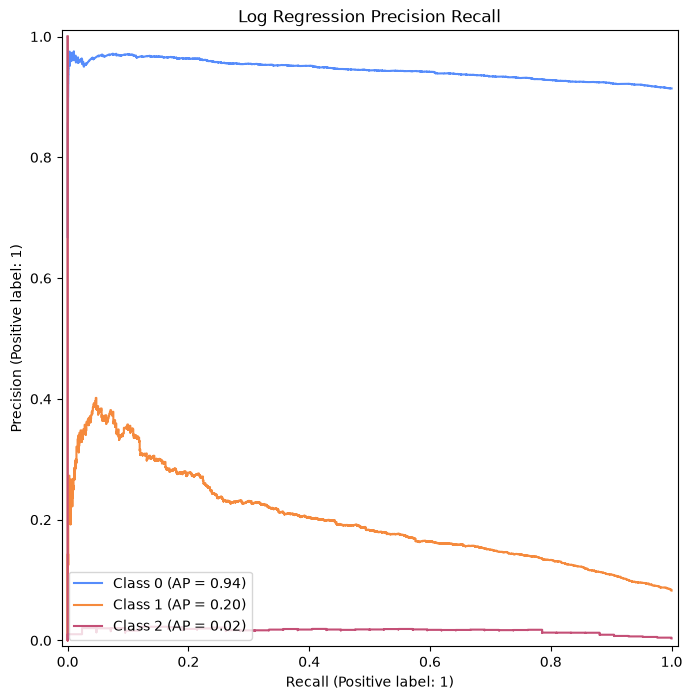

Macro Average Precision Score: 0.387


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categor

SGD Classifier Test Cross Val Accuracy: 0.4166 (0.0490)
SGD Classifier Test Cross Val Balanced Accuracy: 0.6406 (0.0098)
SGD Classifier Test Cross Val F1 Macro: 0.2679 (0.0232)
SGD Classifier Test Cross Val ROC AUC: 0.7360 (0.0104)


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/linear_model/_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


Classification Report
              precision    recall  f1-score   support

           0       0.95      0.51      0.66     11415
           1       0.16      0.62      0.25      1031
           2       0.01      0.76      0.03        42

    accuracy                           0.52     12488
   macro avg       0.37      0.63      0.31     12488
weighted avg       0.88      0.52      0.63     12488

Confusion Matrix
[[5808 3396 2211]
 [ 307  636   88]
 [   5    5   32]]


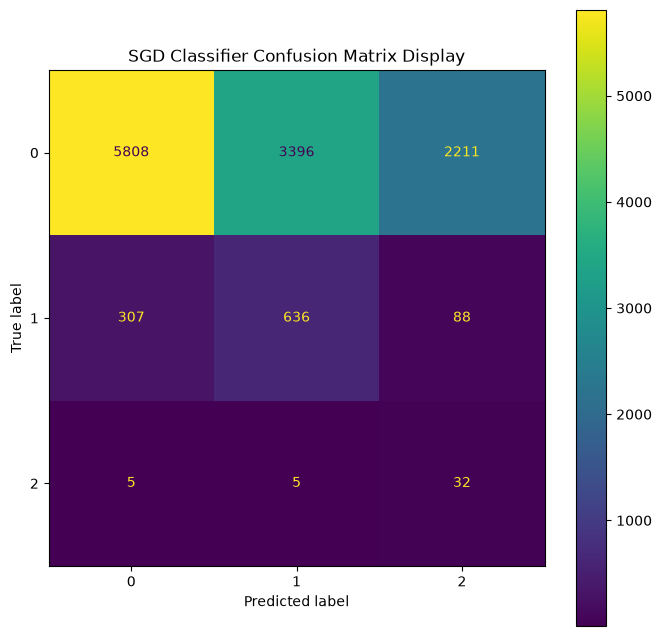

0 [0.73 0.32 0.32 ... 0.41 0.4  0.31]
1 [0.27 0.02 0.03 ... 0.59 0.6  0.69]
2 [8.17e-05 6.57e-01 6.51e-01 ... 1.49e-03 1.13e-04 6.83e-04]


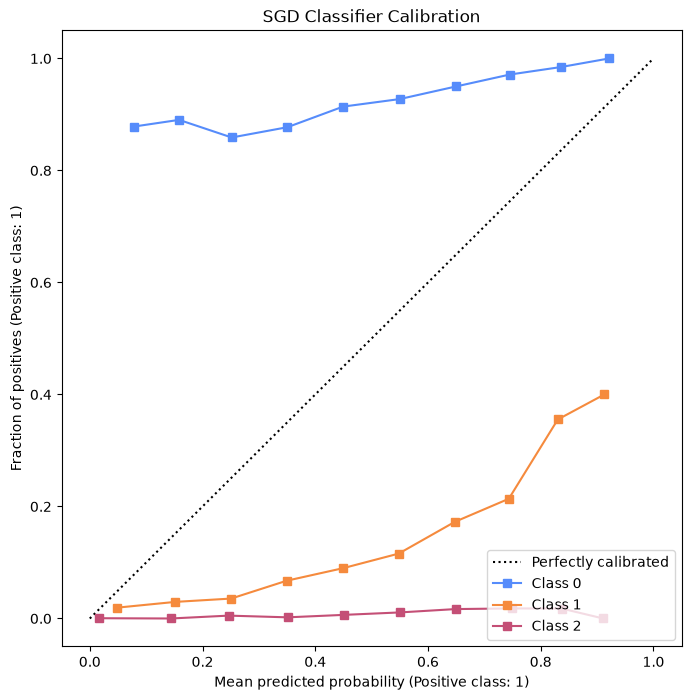

0 [0.73 0.32 0.32 ... 0.41 0.4  0.31]
1 [0.27 0.02 0.03 ... 0.59 0.6  0.69]
2 [8.17e-05 6.57e-01 6.51e-01 ... 1.49e-03 1.13e-04 6.83e-04]


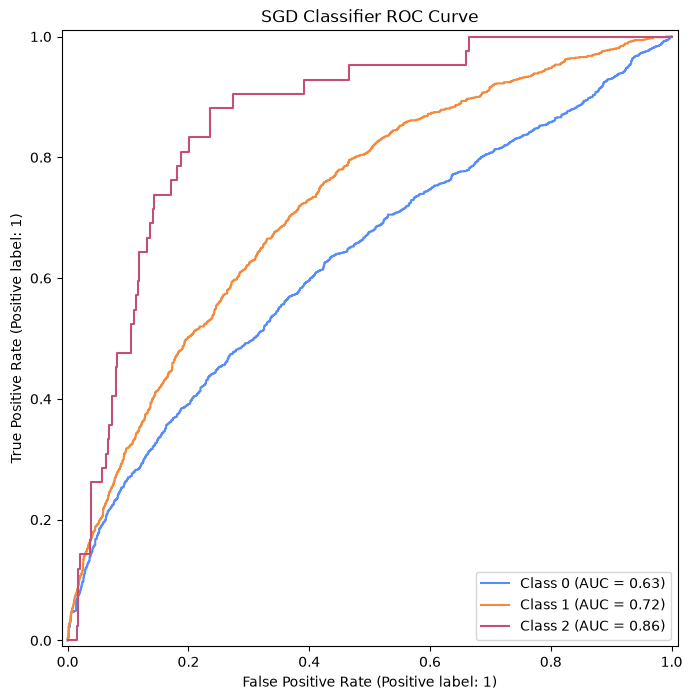

0 [0.73 0.32 0.32 ... 0.41 0.4  0.31]
1 [0.27 0.02 0.03 ... 0.59 0.6  0.69]
2 [8.17e-05 6.57e-01 6.51e-01 ... 1.49e-03 1.13e-04 6.83e-04]


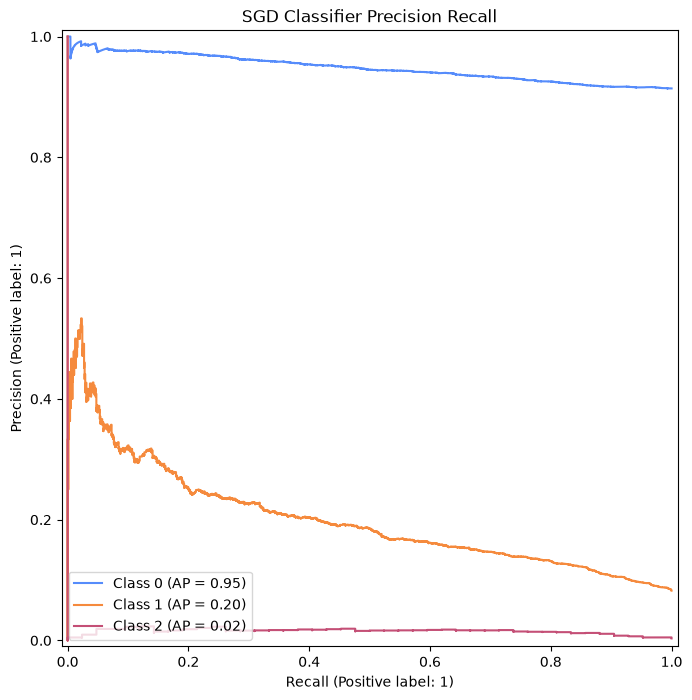

Macro Average Precision Score: 0.388


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


K-Neighbours Classifier Test Cross Val Accuracy: 0.7349 (0.0088)
K-Neighbours Classifier Test Cross Val Balanced Accuracy: 0.6275 (0.0130)
K-Neighbours Classifier Test Cross Val F1 Macro: 0.4180 (0.0063)
K-Neighbours Classifier Test Cross Val ROC AUC: 0.7638 (0.0004)
Classification Report
              precision    recall  f1-score   support

           0       0.97      0.77      0.86     11415
           1       0.24      0.74      0.36      1031
           2       0.07      0.48      0.12        42

    accuracy                           0.76     12488
   macro avg       0.43      0.66      0.45     12488
weighted avg       0.91      0.76      0.81     12488

Confusion Matrix
[[8741 2421  253]
 [ 260  764    7]
 [  17    5   20]]


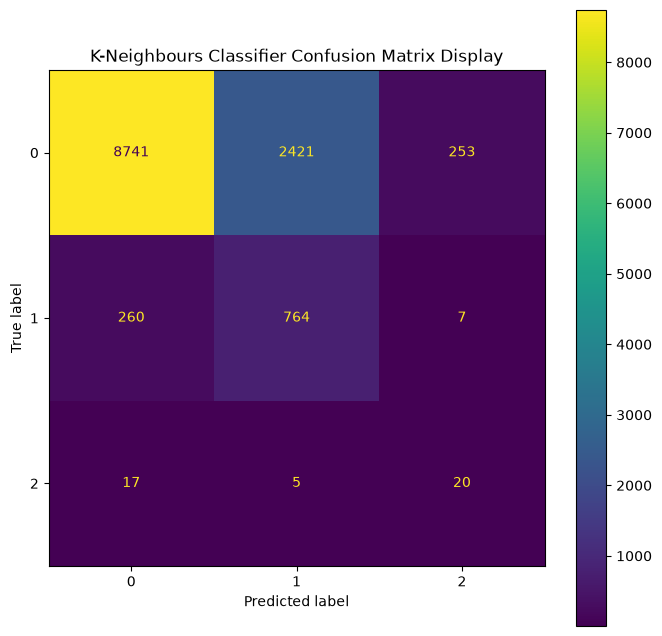

0 [1.  1.  0.6 ... 0.  1.  1. ]
1 [0.  0.  0.4 ... 1.  0.  0. ]
2 [0. 0. 0. ... 0. 0. 0.]


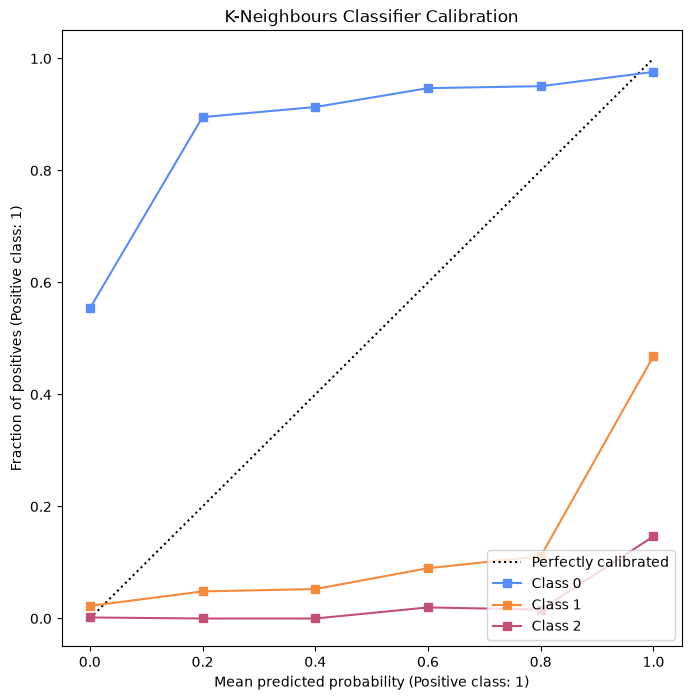

0 [1.  1.  0.6 ... 0.  1.  1. ]
1 [0.  0.  0.4 ... 1.  0.  0. ]
2 [0. 0. 0. ... 0. 0. 0.]


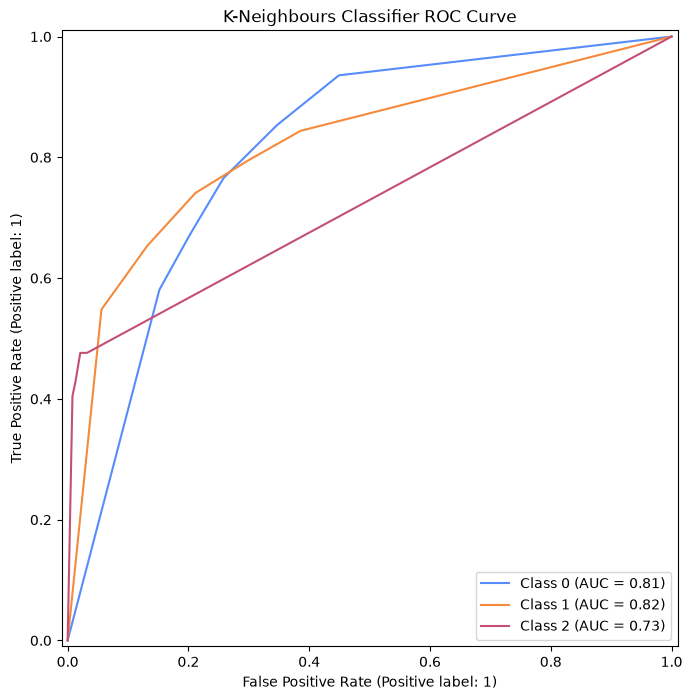

0 [1.  1.  0.6 ... 0.  1.  1. ]
1 [0.  0.  0.4 ... 1.  0.  0. ]
2 [0. 0. 0. ... 0. 0. 0.]


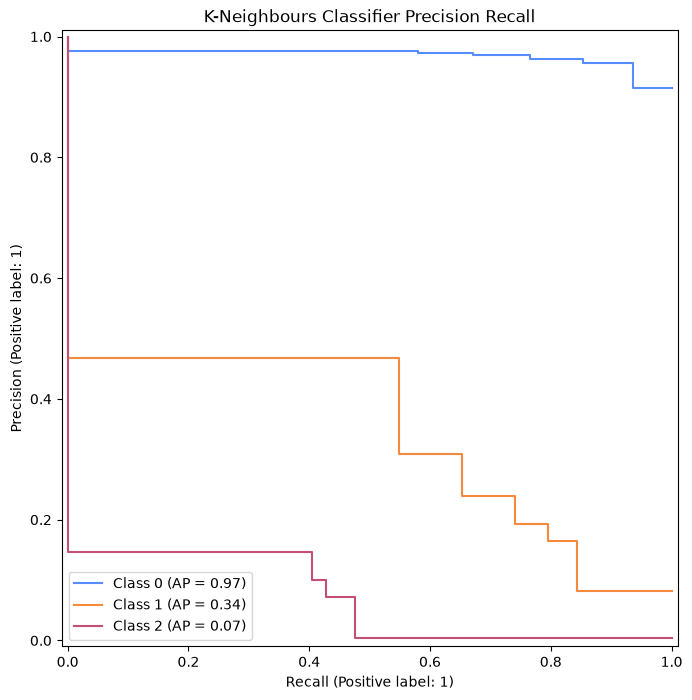

Macro Average Precision Score: 0.459


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Decision Tree Classifier Test Cross Val Accuracy: 0.7332 (0.0134)
Decision Tree Classifier Test Cross Val Balanced Accuracy: 0.5321 (0.0084)
Decision Tree Classifier Test Cross Val F1 Macro: 0.3884 (0.0068)
Decision Tree Classifier Test Cross Val ROC AUC: 0.7043 (0.0049)
Classification Report
              precision    recall  f1-score   support

           0       0.95      0.73      0.83     11415
           1       0.19      0.60      0.29      1031
           2       0.02      0.31      0.04        42

    accuracy                           0.72     12488
   macro avg       0.39      0.55      0.39     12488
weighted avg       0.89      0.72      0.78     12488

Confusion Matrix
[[8317 2597  501]
 [ 391  617   23]
 [  21    8   13]]


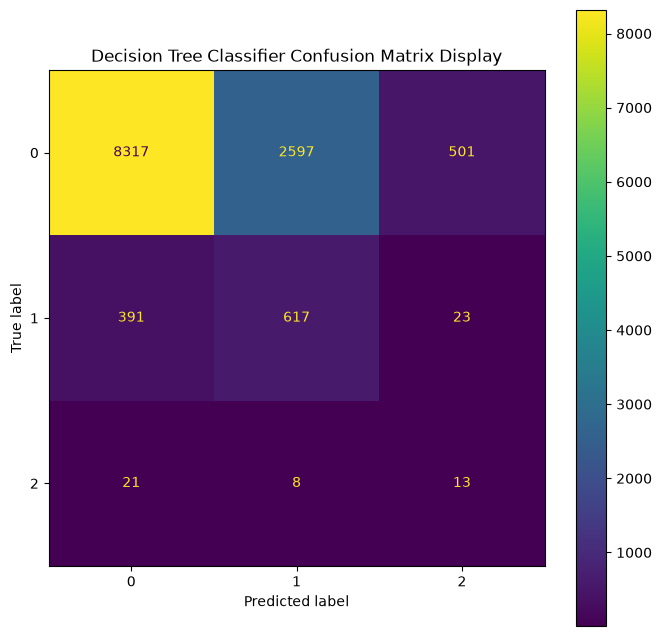

0 [1.   1.   0.78 ... 0.59 0.22 0.75]
1 [0.   0.   0.18 ... 0.41 0.78 0.25]
2 [0.   0.   0.04 ... 0.   0.   0.  ]


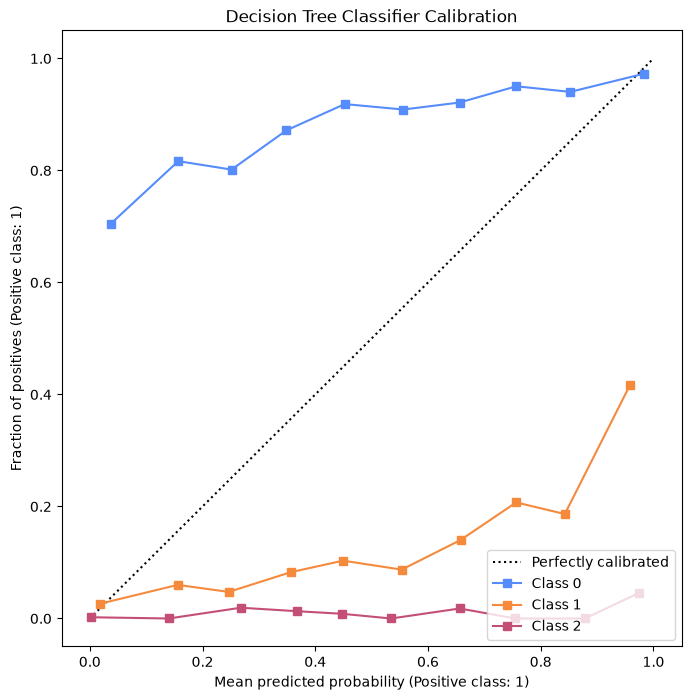

0 [1.   1.   0.78 ... 0.59 0.22 0.75]
1 [0.   0.   0.18 ... 0.41 0.78 0.25]
2 [0.   0.   0.04 ... 0.   0.   0.  ]


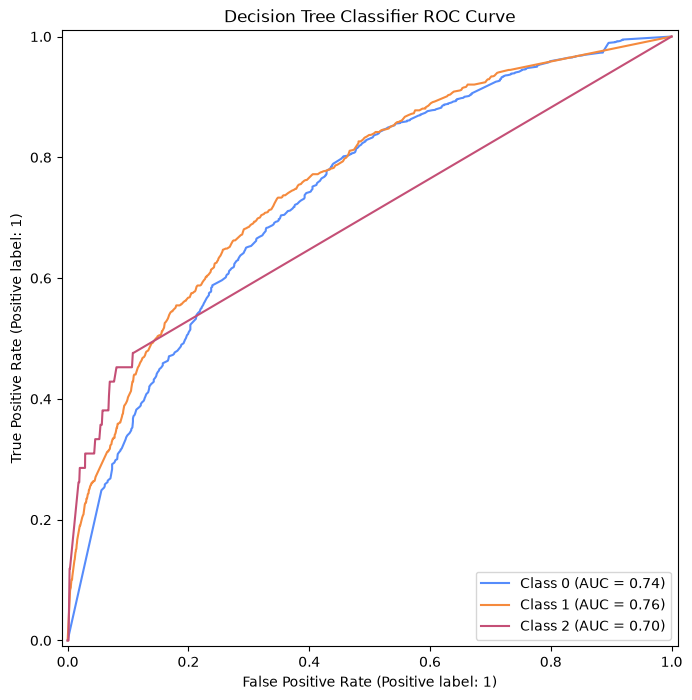

0 [1.   1.   0.78 ... 0.59 0.22 0.75]
1 [0.   0.   0.18 ... 0.41 0.78 0.25]
2 [0.   0.   0.04 ... 0.   0.   0.  ]


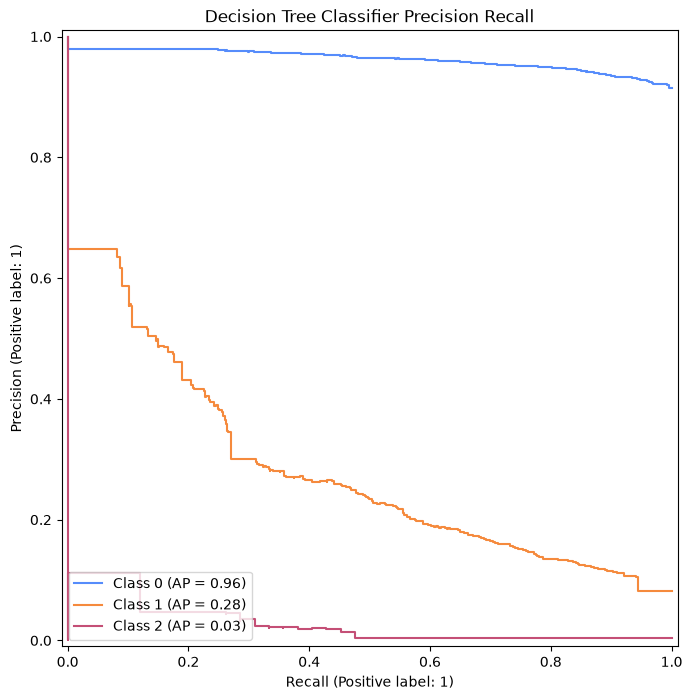

Macro Average Precision Score: 0.423


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Linear SVC Test Cross Val Accuracy: 0.1750 (0.0429)
Linear SVC Test Cross Val Balanced Accuracy: 0.5902 (0.0167)
Linear SVC Test Cross Val F1 Macro: 0.1384 (0.0284)


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Classification Report
              precision    recall  f1-score   support

           0       0.96      0.01      0.02     11415
           1       0.10      0.87      0.18      1031
           2       0.01      0.83      0.02        42

    accuracy                           0.09     12488
   macro avg       0.36      0.57      0.07     12488
weighted avg       0.89      0.09      0.04     12488

Confusion Matrix
[[ 132 8247 3036]
 [   4  902  125]
 [   1    6   35]]


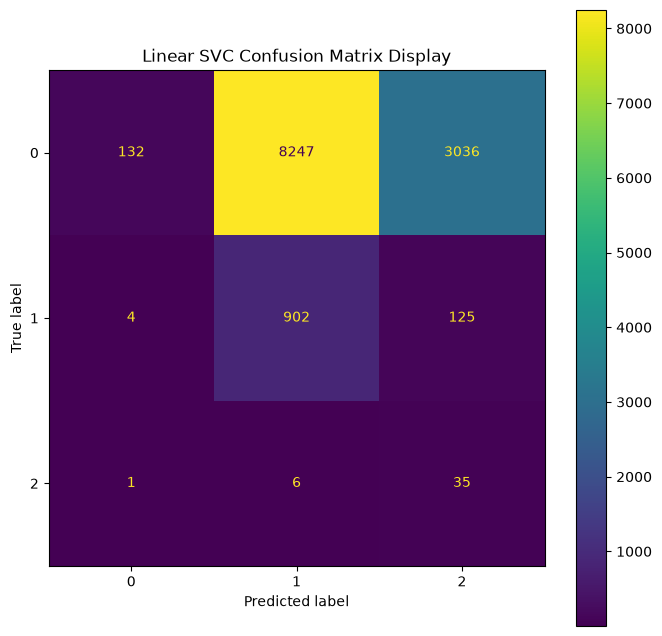

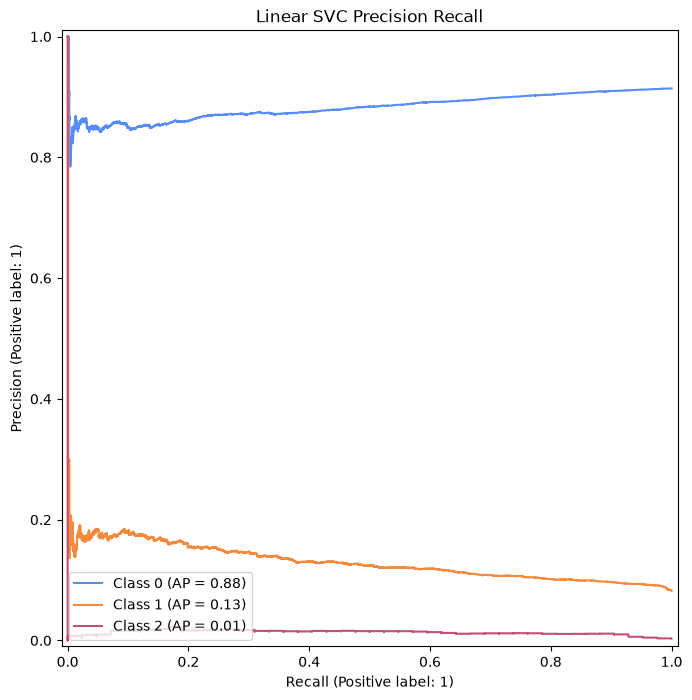

Macro Average Precision Score: 0.342


/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/home/alex/dev/MSC_UOL/csm500-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Linear Discriminant Analysis Test Cross Val Accuracy: 0.5008 (0.0092)
Linear Discriminant Analysis Test Cross Val Balanced Accuracy: 0.6319 (0.0039)
Linear Discriminant Analysis Test Cross Val F1 Macro: 0.3048 (0.0043)
Linear Discriminant Analysis Test Cross Val ROC AUC: 0.7339 (0.0084)
Classification Report
              precision    recall  f1-score   support

           0       0.95      0.48      0.64     11415
           1       0.16      0.65      0.26      1031
           2       0.01      0.79      0.03        42

    accuracy                           0.50     12488
   macro avg       0.37      0.64      0.31     12488
weighted avg       0.88      0.50      0.61     12488

Confusion Matrix
[[5508 3525 2382]
 [ 276  669   86]
 [   8    1   33]]


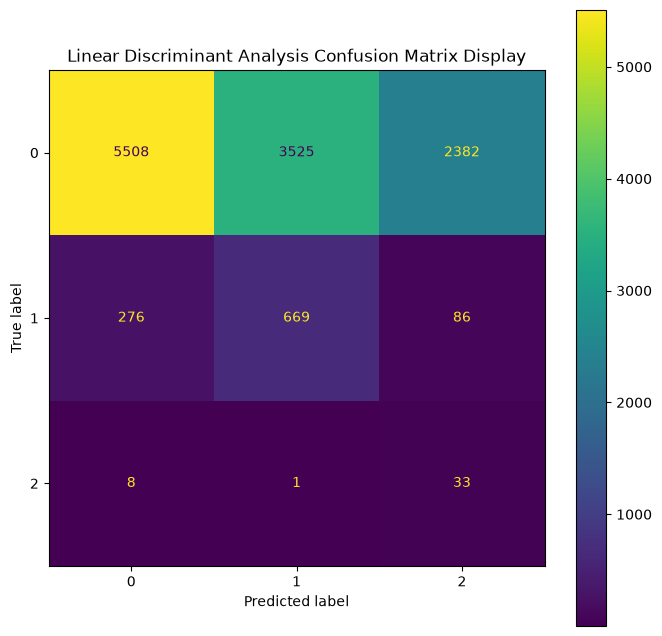

0 [0.83 0.11 0.12 ... 0.31 0.19 0.17]
1 [0.17 0.01 0.01 ... 0.69 0.81 0.82]
2 [1.46e-03 8.74e-01 8.63e-01 ... 1.50e-03 1.06e-04 4.37e-03]


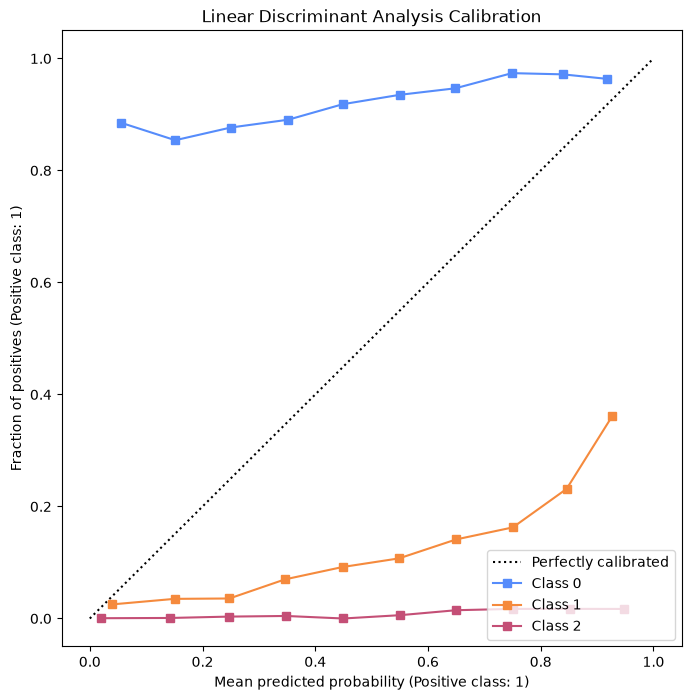

0 [0.83 0.11 0.12 ... 0.31 0.19 0.17]
1 [0.17 0.01 0.01 ... 0.69 0.81 0.82]
2 [1.46e-03 8.74e-01 8.63e-01 ... 1.50e-03 1.06e-04 4.37e-03]


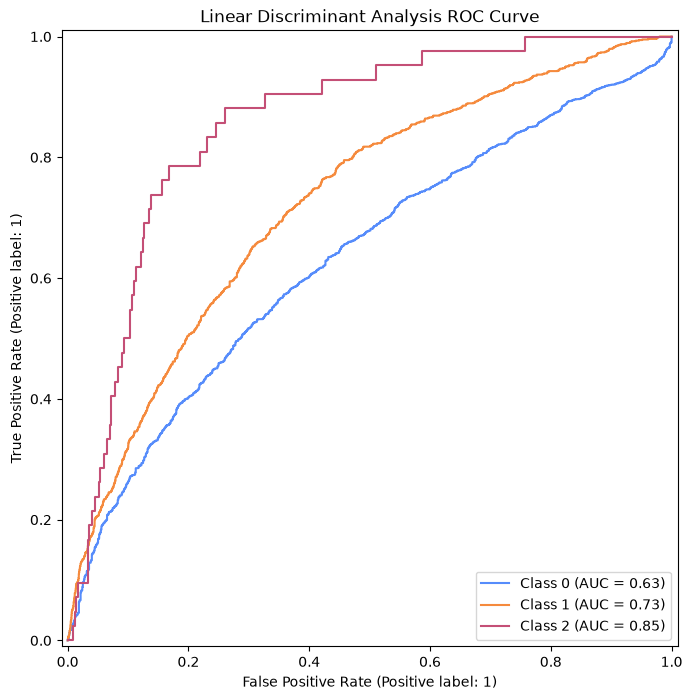

0 [0.83 0.11 0.12 ... 0.31 0.19 0.17]
1 [0.17 0.01 0.01 ... 0.69 0.81 0.82]
2 [1.46e-03 8.74e-01 8.63e-01 ... 1.50e-03 1.06e-04 4.37e-03]


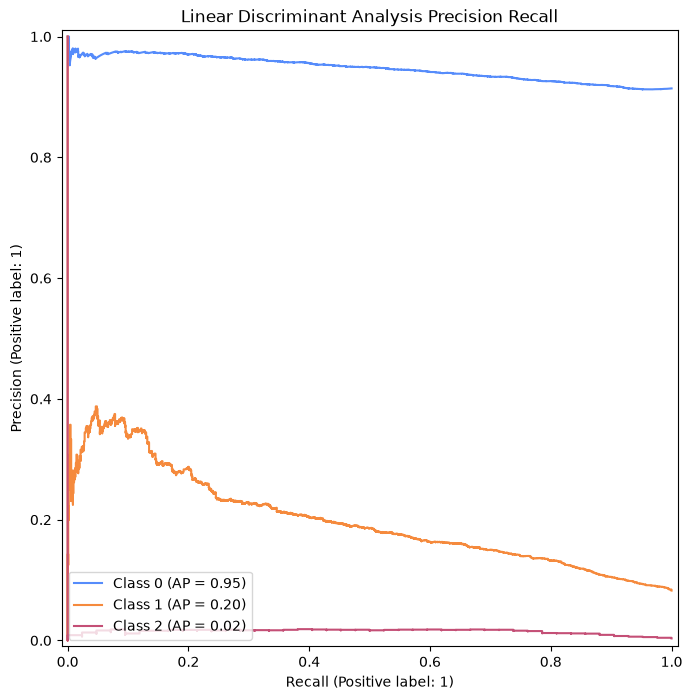

Macro Average Precision Score: 0.387


[]

In [4]:
build_model_pipeline = get_build_model_pipeline(CONTINUOUS_DATA_FIELDS, DROPPED_CATEGORIES,
                                                X_ORDINAL_ENCODED_CATEGORIES,
                                                HIGH_CARDINALITY_ENCODED_CATEGORIES, LOW_CARDINALITY_ENCODED_CATEGORIES)

# run_model_pipeline(build_model_pipeline, primary_x_train, primary_y_train, primary_x_test, primary_y_test)
pipelines = run_model_pipeline(build_model_pipeline, physical_x_train, physical_y_train, physical_x_test,
                               physical_y_test)

In [5]:
pipelines

[]